==================== Q1 ====================


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Hindi Predictions: [1 1 0 0]
Accuracy: 1.0
Cosine Similarity:
[[0.921 0.361]
 [0.344 0.96 ]]

==================== Q2 ====================
Training completed
Final training loss: 0.016256172209978104

Training-set decoding:
hi       -> salut      (reference: salut)
no       -> non        (reference: non)
go       -> va         (reference: va)
ok       -> oui        (reference: oui)
cat      -> chat       (reference: chat)
dog      -> chien      (reference: chien)
hello    -> bonjour    (reference: bonjour)
thanks   -> merci      (reference: merci)

Unseen inputs:
hey      -> salut
god      -> cha
cot      -> chien
hell     -> bonjour

Character-level BLEU: 0.929
Exact-match accuracy: 1.0

==================== Q3 ====================


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Text: Narendra Modi visited New Delhi.
{'word': 'Narendra Modi', 'label': 'PER', 'confidence': 0.998}
{'word': 'New Delhi', 'label': 'LOC', 'confidence': 1.0}

Text: Rahul Gandhi visited India.
{'word': 'Rahul Gandhi', 'label': 'PER', 'confidence': 0.983}
{'word': 'India', 'label': 'LOC', 'confidence': 1.0}

Text: राहुल गांधी ने नई दिल्ली का दौरा किया।
{'word': 'राहुल गांधी', 'label': 'PER', 'confidence': 0.999}
{'word': 'नई दिल्ली', 'label': 'LOC', 'confidence': 0.994}

Original: Narendra Modi visited New Delhi.
Tokens: ['Na', '##rend', '##ra', 'Mod', '##i', 'visited', 'New', 'Delhi', '.']

Original: राहुल गांधी नई दिल्ली गए।
Tokens: ['र', '##ाह', '##ुल', 'गां', '##धी', 'नई', 'दिल्ली', 'गए', '।']

==================== Q4 ====================
Cluster Labels: [0 0 0 0 0 0 1 1 1 1 1 1]
Silhouette Score: 0.482


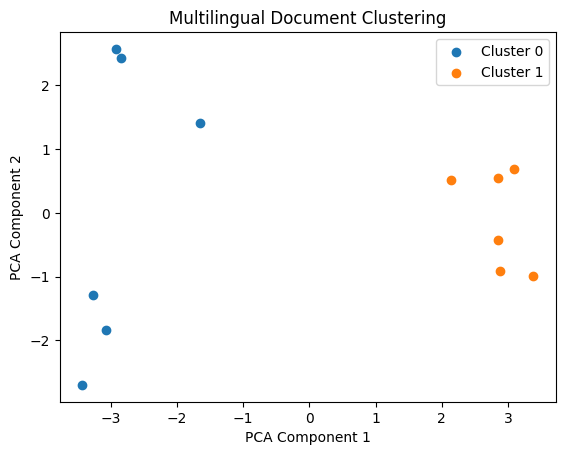

In [5]:
!pip -q install sentence-transformers scikit-learn transformers torch matplotlib nltk

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from transformers import pipeline

# ======================= Q1: Cross-lingual sentiment =======================
print("=" * 20, "Q1", "=" * 20)
st_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

train_texts = [
    "I love this movie", "This product is excellent", "I am very happy", "This is wonderful",
    "I hate this movie", "This product is terrible", "I am very disappointed", "This is awful",
]
train_labels = [1, 1, 1, 1, 0, 0, 0, 0]

clf = LogisticRegression()
clf.fit(st_model.encode(train_texts), train_labels)

hindi_texts = [
    "यह फिल्म बहुत अच्छी है",
    "यह उत्पाद शानदार है",
    "मुझे यह फिल्म पसंद नहीं है",
    "यह बहुत खराब है",
]
hindi_labels = [1, 1, 0, 0]

predictions = clf.predict(st_model.encode(hindi_texts))
print("Hindi Predictions:", predictions)
print("Accuracy:", accuracy_score(hindi_labels, predictions))

english = ["I am happy", "This movie is good"]
hindi = ["मैं खुश हूँ", "यह फिल्म अच्छी है"]
print("Cosine Similarity:")
print(np.round(cosine_similarity(st_model.encode(english), st_model.encode(hindi)), 3))

# ======================= Q2: Seq2Seq LSTM =======================
print("\n" + "=" * 20, "Q2", "=" * 20)
tf.random.set_seed(42)
np.random.seed(42)

pairs = [
    ("hi", "salut"), ("no", "non"), ("go", "va"), ("ok", "oui"),
    ("cat", "chat"), ("dog", "chien"), ("hello", "bonjour"), ("thanks", "merci"),
]

START, END = "^", "$"
src_chars = sorted(set("".join(x for x, y in pairs)))
tgt_chars = sorted(set("".join(y for x, y in pairs)) | {START, END})

src_vocab = {"<PAD>": 0}
tgt_vocab = {"<PAD>": 0}
for c in src_chars: src_vocab[c] = len(src_vocab)
for c in tgt_chars: tgt_vocab[c] = len(tgt_vocab)
inv_tgt = {i: c for c, i in tgt_vocab.items()}

max_src = max(len(x) for x, y in pairs)
max_tgt = max(len(y) + 1 for x, y in pairs)

X = np.zeros((len(pairs), max_src), dtype="int32")
decoder_X = np.zeros((len(pairs), max_tgt), dtype="int32")
decoder_Y = np.zeros((len(pairs), max_tgt), dtype="int32")

for i, (src, tgt) in enumerate(pairs):
    X[i, :len(src)] = [src_vocab[c] for c in src]
    dec_in, dec_tgt = START + tgt, tgt + END
    decoder_X[i, :len(dec_in)] = [tgt_vocab[c] for c in dec_in]
    decoder_Y[i, :len(dec_tgt)] = [tgt_vocab[c] for c in dec_tgt]

LATENT = 64

encoder_input = layers.Input(shape=(max_src,))
enc_emb = layers.Embedding(len(src_vocab), LATENT, mask_zero=True)(encoder_input)
_, state_h, state_c = layers.LSTM(LATENT, return_state=True)(enc_emb)

decoder_input = layers.Input(shape=(max_tgt,))
dec_embedding = layers.Embedding(len(tgt_vocab), LATENT, mask_zero=True)
decoder_lstm = layers.LSTM(LATENT, return_sequences=True, return_state=True)
decoder_dense = layers.Dense(len(tgt_vocab), activation="softmax")

dec_out, _, _ = decoder_lstm(dec_embedding(decoder_input), initial_state=[state_h, state_c])
output = decoder_dense(dec_out)

seq_model = Model([encoder_input, decoder_input], output)
seq_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
history = seq_model.fit([X, decoder_X], decoder_Y, epochs=300, verbose=0)
print("Training completed")
print("Final training loss:", history.history["loss"][-1])

# Inference models
encoder_model = Model(encoder_input, [state_h, state_c])
dec_state_h = layers.Input(shape=(LATENT,))
dec_state_c = layers.Input(shape=(LATENT,))
dec_token = layers.Input(shape=(1,))
step_out, h, c = decoder_lstm(dec_embedding(dec_token), initial_state=[dec_state_h, dec_state_c])
decoder_model = Model([dec_token, dec_state_h, dec_state_c], [decoder_dense(step_out), h, c])

def translate(word):
    ids = [src_vocab[c] for c in word if c in src_vocab][:max_src]
    seq = np.zeros((1, max_src), dtype="int32")
    seq[0, :len(ids)] = ids
    h, c = encoder_model.predict(seq, verbose=0)
    token, result = tgt_vocab[START], ""
    for _ in range(max_tgt + 3):
        probs, h, c = decoder_model.predict([np.array([[token]]), h, c], verbose=0)
        token = int(np.argmax(probs[0, -1]))
        ch = inv_tgt.get(token, "")
        if ch in (END, ""):
            break
        result += ch
    return result

print("\nTraining-set decoding:")
for src, tgt in pairs:
    print(f"{src:8s} -> {translate(src):10s} (reference: {tgt})")

print("\nUnseen inputs:")
for w in ["hey", "god", "cot", "hell"]:
    print(f"{w:8s} -> {translate(w)}")

refs = [[list(t)] for _, t in pairs]
hyps = [list(translate(s)) for s, _ in pairs]
bleu = corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)
exact = np.mean([translate(s) == t for s, t in pairs])
print("\nCharacter-level BLEU:", round(bleu, 3))
print("Exact-match accuracy:", round(float(exact), 3))

# ======================= Q3: Cross-lingual NER =======================
print("\n" + "=" * 20, "Q3", "=" * 20)
ner = pipeline(
    "ner",
    model="Davlan/bert-base-multilingual-cased-ner-hrl",
    aggregation_strategy="simple",
)

ner_texts = [
    "Narendra Modi visited New Delhi.",
    "Rahul Gandhi visited India.",
    "राहुल गांधी ने नई दिल्ली का दौरा किया।",
]

for text in ner_texts:
    print("\nText:", text)
    for e in ner(text):
        print({"word": e["word"], "label": e["entity_group"], "confidence": round(float(e["score"]), 3)})

tokenizer = ner.tokenizer
for text in ["Narendra Modi visited New Delhi.", "राहुल गांधी नई दिल्ली गए।"]:
    print("\nOriginal:", text)
    print("Tokens:", tokenizer.tokenize(text))

# ======================= Q4: Multilingual clustering =======================
print("\n" + "=" * 20, "Q4", "=" * 20)
docs = [
    "The football team won the match",
    "The player scored a goal",
    "El equipo ganó el partido",
    "El jugador marcó un gol",
    "फुटबॉल टीम ने मैच जीता",
    "खिलाड़ी ने गोल किया",

    "The doctor treated the patient",
    "The hospital provides medical care",
    "El médico atendió al paciente",
    "El hospital ofrece atención médica",
    "डॉक्टर ने मरीज का इलाज किया",
    "अस्पताल में मरीजों की देखभाल होती है",
]

embeddings = st_model.encode(docs)
labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(embeddings)
print("Cluster Labels:", labels)
print("Silhouette Score:", round(silhouette_score(embeddings, labels), 3))

points = PCA(n_components=2).fit_transform(embeddings)
for cluster in sorted(set(labels)):
    idx = labels == cluster
    plt.scatter(points[idx, 0], points[idx, 1], label=f"Cluster {cluster}")

plt.title("Multilingual Document Clustering")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.show()